In [ ]:
%pip install dowhy graphviz

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

df = pd.read_csv("project1_algorithmic_pricing_synthetic_dataset.csv")
df["date"] = pd.to_datetime(df["date"])

print("Dataset shape:", df.shape)
print(df.columns.tolist())

Dataset shape: (540, 11)
['date', 'region', 'product_category', 'our_price', 'competitor_price', 'units_sold', 'revenue', 'marketing_spend', 'promotion_active', 'treatment', 'period']


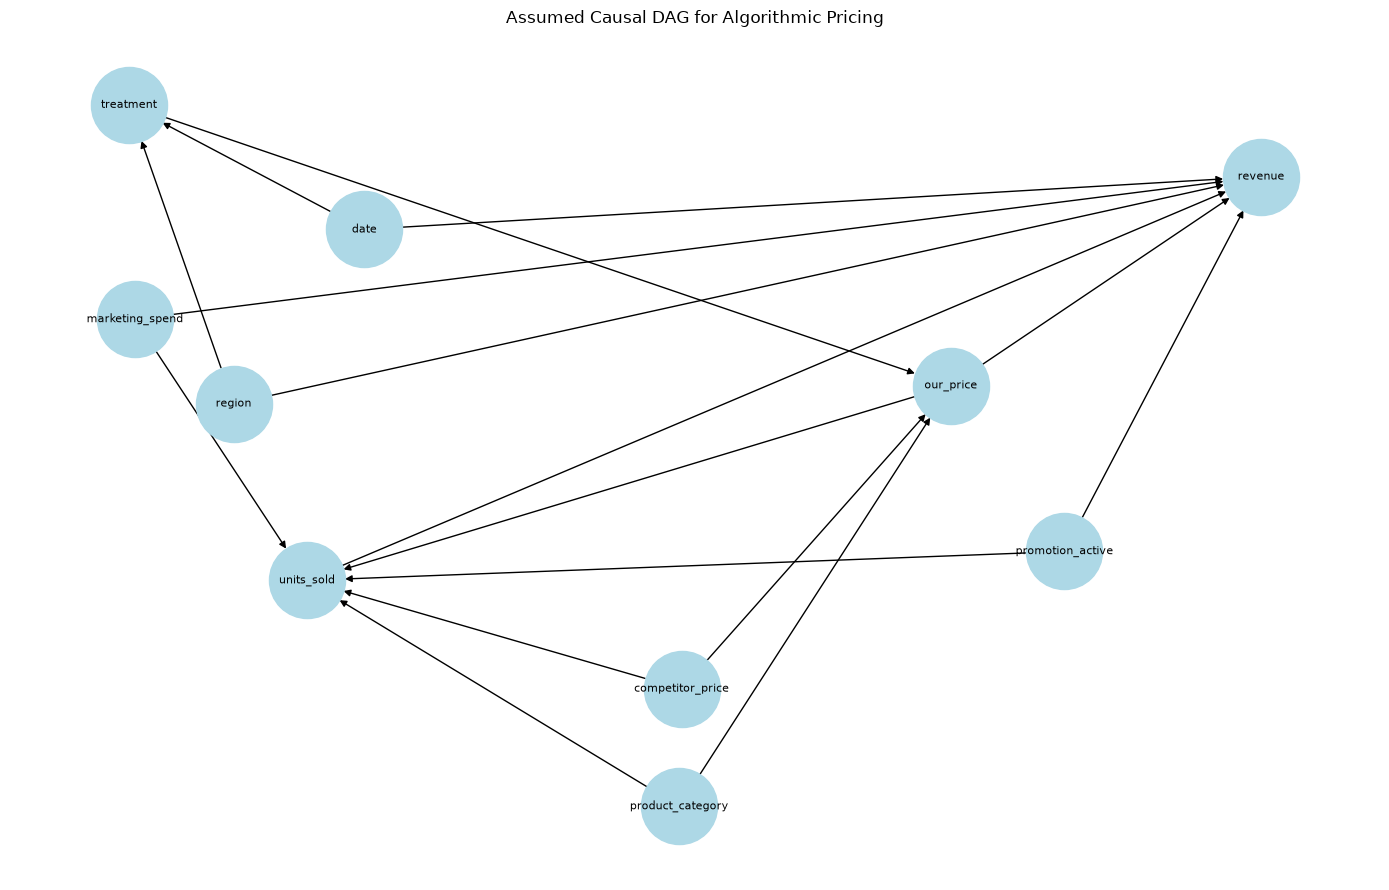

In [2]:
edges = [
    ("competitor_price", "our_price"),
    ("competitor_price", "units_sold"),
    ("treatment", "our_price"),
    ("our_price", "units_sold"),
    ("our_price", "revenue"),
    ("units_sold", "revenue"),
    ("marketing_spend", "units_sold"),
    ("marketing_spend", "revenue"),
    ("promotion_active", "units_sold"),
    ("promotion_active", "revenue"),
    ("region", "treatment"),
    ("region", "revenue"),
    ("date", "treatment"),
    ("date", "revenue"),
    ("product_category", "our_price"),
    ("product_category", "units_sold")
]

G = nx.DiGraph()
G.add_edges_from(edges)

plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G, pos,
    with_labels=True,
    node_size=3000,
    node_color="lightblue",
    font_size=8,
    arrows=True
)

plt.title("Assumed Causal DAG for Algorithmic Pricing")
plt.axis("off")
plt.tight_layout()
plt.savefig("03_causal_dag.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
import networkx as nx
from networkx.algorithms.d_separation import is_d_separator

nx.algorithms.d_separated = is_d_separator
nx.d_separated = is_d_separator

print("NetworkX compatibility fix applied")

NetworkX compatibility fix applied


In [5]:
identified_estimand = model.identify_effect()
print(identified_estimand)

Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                              
────────────(E[revenue|date,region])
d[treatment]                        
Estimand assumption 1, Unconfoundedness: If U→{treatment} and U→revenue then P(revenue|treatment,date,region,U) = P(revenue|treatment,date,region)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

